# 10. K-Means and Silhouette Score (mockup)

**K-means** is unsupervised: it groups quarters into **k clusters** of similar lagged macro conditions without looking at the target. Here the clusters act as economic **regimes**, and we then check whether charge-offs differ by regime.
- **Scaling is required** (distance-based), fit on the training period only.
- Lags of the target (`co_other_cons_L*`) are left out, so the regimes come from the macro and credit features alone.
- **Choosing k:** *inertia* (within-cluster spread) always falls as k grows, so look for the elbow. The **silhouette score** (−1 to 1) measures how much closer each quarter is to its own cluster than to the next nearest; higher is better.
- Test quarters (2015+) are **assigned** to the training clusters, never used to fit them.

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)


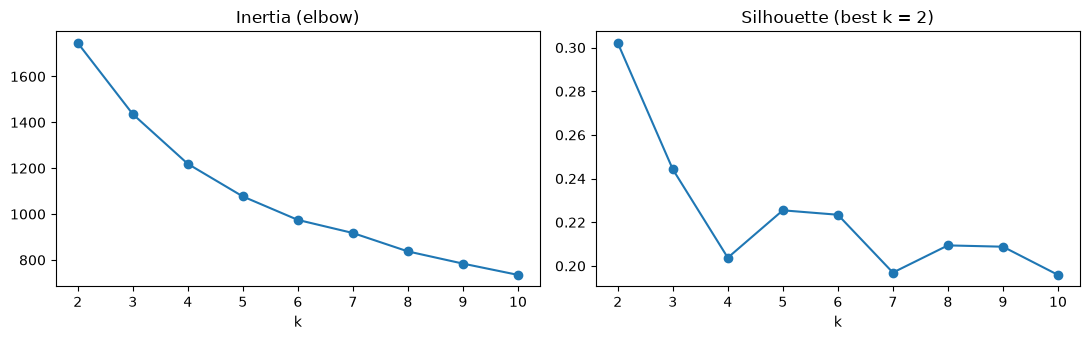

In [1]:
from prep import *
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_train, X_test, y_train, y_test, meta = load_model_data()
feats = [c for c in X_train.columns if not c.startswith("co_other_cons")]
prep_ = make_pipeline(*preprocess(scale=True)).fit(X_train[feats])          # train-only scaling
Z_train, Z_test = prep_.transform(X_train[feats]), prep_.transform(X_test[feats])

ks = range(2, 11)
fits = {k: KMeans(k, n_init=10, random_state=0).fit(Z_train) for k in ks}
sil = pd.Series({k: silhouette_score(Z_train, m.labels_) for k, m in fits.items()})
inertia = pd.Series({k: m.inertia_ for k, m in fits.items()})
best_k = sil.idxmax()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
inertia.plot(ax=ax[0], marker="o", title="Inertia (elbow)"); sil.plot(ax=ax[1], marker="o", title=f"Silhouette (best k = {best_k})")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

,train quarters,test quarters,mean charge-off (train),mean charge-off (test)
0,67,37,1.003,0.815
1,25,7,1.878,0.986


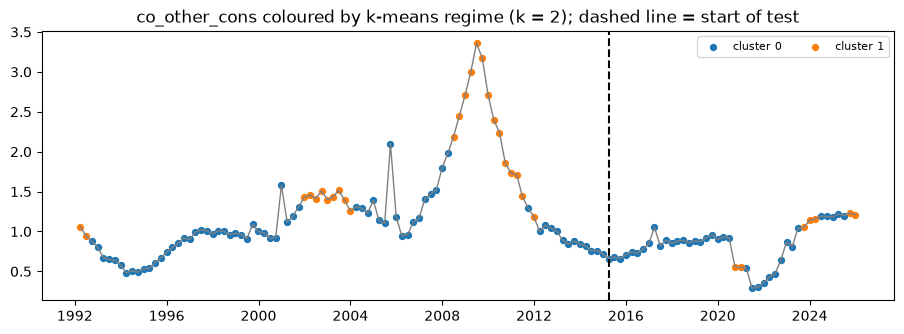

In [2]:
km = fits[best_k]
lab = pd.concat([pd.Series(km.labels_, X_train.index), pd.Series(km.predict(Z_test), X_test.index)])
y_all = pd.concat([y_train, y_test])

# regime profile: size and average charge-off rate (train vs test)
display(pd.DataFrame({"train quarters": lab[:len(y_train)].value_counts(),
                      "test quarters": lab[len(y_train):].value_counts(),
                      "mean charge-off (train)": y_train.groupby(lab[:len(y_train)]).mean(),
                      "mean charge-off (test)": y_test.groupby(lab[len(y_train):]).mean()}).round(3).fillna(0))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(y_all.index, y_all, color="grey", lw=1)
for c in sorted(lab.unique()):
    ax.scatter(lab.index[lab == c], y_all[lab == c], s=18, label=f"cluster {c}")
ax.axvline(X_test.index[0], ls="--", color="k"); ax.legend(ncol=best_k, fontsize=8)
ax.set_title(f"{meta['target']} coloured by k-means regime (k = {best_k}); dashed line = start of test")
plt.show()

The k-means result as a diagnostic rather than a fix. It shows that the macro data signalled stress in 2020 while charge-offs fell, which supports your argument that 2020–21 was a policy-driven break the features couldn’t capture.